# Human kidney spatial ATAC-seq resolution 20mm

In [1]:
from file_utils import *

In [3]:
adata = ad.read_h5ad(main_path + "human_kidney_20mm_spATACseq_TFactivity_gene-activity_clone.h5ad")
adata

AnnData object with n_obs × n_vars = 55206 × 248455
    obs: 'Sample', 'TSSEnrichment', 'ReadsInTSS', 'ReadsInPromoter', 'ReadsInBlacklist', 'PromoterRatio', 'PassQC', 'NucleosomeRatio', 'nMultiFrags', 'nMonoFrags', 'nFrags', 'nDiFrags', 'BlacklistRatio', 'Clusters', 'Clusters2', 'ReadsInPeaks', 'FRIP', 'barcode', 'in_tissue', 'array_row', 'array_col', 'pxl_row_in_fullres', 'pxl_col_in_fullres', 'Trajectory', 'clone', 'clone_celltype', 'label', 'PT_clone', 'PT_clone_celltype'
    var: 'seqnames', 'idx', 'start', 'end'
    uns: 'Clusters2_colors', 'spatial'
    obsm: 'TFactivity', 'X_diffmap', 'X_harmony', 'X_umap', 'gene_activity', 'spatial', 'spatial_rotated'

# Quality control

In [4]:
plot_quality_control(adata)

# Spatial ATAC-seq UMAP

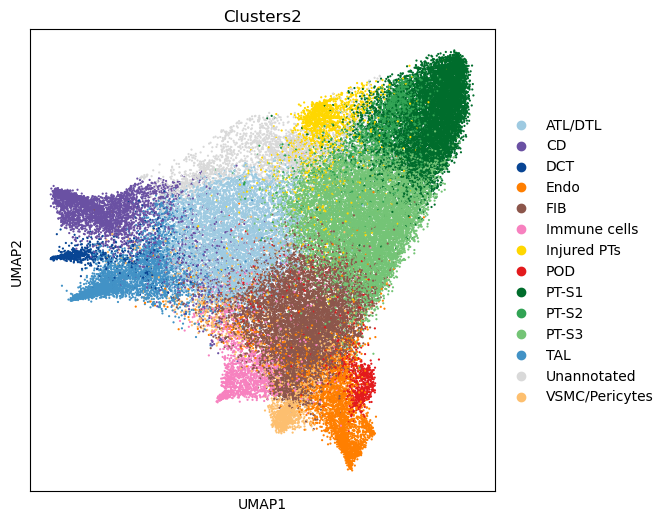

In [5]:
with mpl.rc_context({'figure.figsize': [6,6],
                             'axes.facecolor': 'white'}):
    sc.pl.umap(adata, color="Clusters2", size = 10)

# Plot cell types annotation for each spatial sample

Healthy_63079
Spatial coordinates shape: (8260, 2)
Expression matrix shape: (8260, 248455)
Spots in tissue: 8260


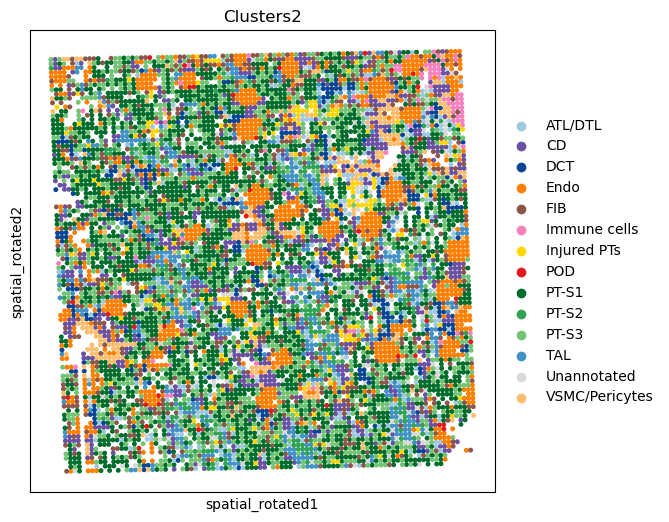

Diseased_57480
Spatial coordinates shape: (8398, 2)
Expression matrix shape: (8398, 248455)
Spots in tissue: 8398


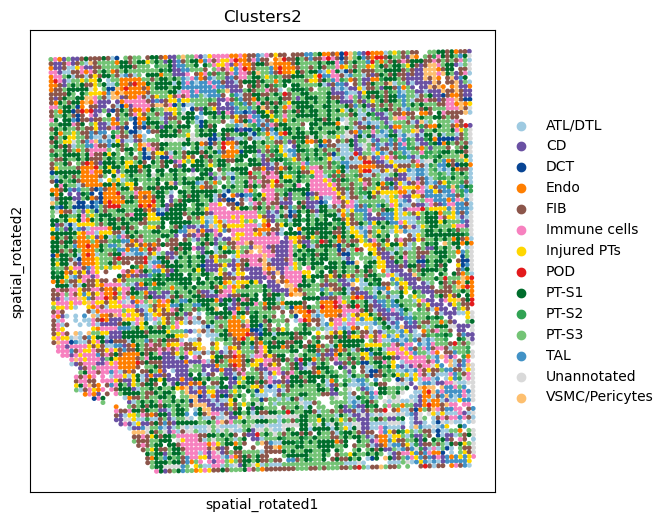

In [6]:
for name in ['Healthy_63079', 'Diseased_57480']:
    print(name)
    slide = select_slide(adata, name, 'Sample')

    # Check spatial data structure
    print("Spatial coordinates shape:", slide.obsm['spatial'].shape)
    print("Expression matrix shape:", slide.X.shape)
    print("Spots in tissue:", sum(slide.obs['in_tissue'] == 1))
    
    with mpl.rc_context({'figure.figsize': [6,6],
                         'axes.facecolor': 'white'}):
        sc.pl.embedding(adata = slide, basis = 'spatial_rotated', 
                        size = 50, color = 'Clusters2')

# Cell compositions changes

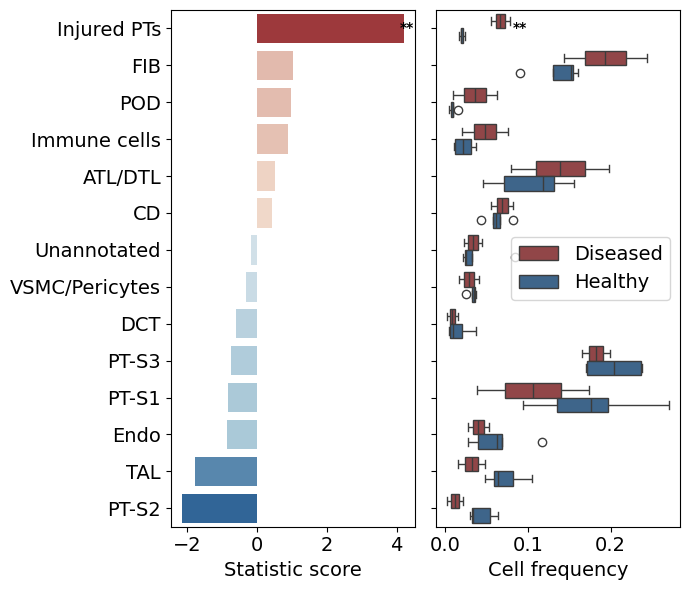

In [7]:
plot_together(adata, adata.obs.Clusters2.unique(),
              group1 = 'Healthy', group2 = 'Diseased',
              my_pal = {'Diseased': '#9d393c', 'Healthy': '#316597'},
              sample_id = 'Sample',
              celltype_id = 'Clusters2',
              label_id = 'label',
              figsize = (7,6))

# Plot gene activity heatmap

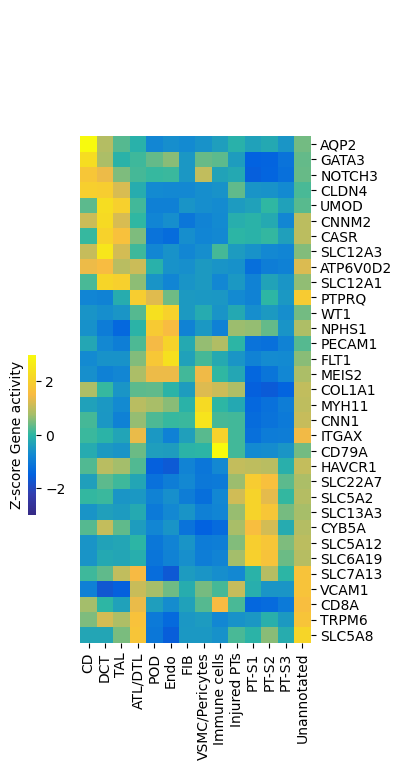

In [8]:
gene_set = ['MEIS2', 'PECAM1', 'WT1', 'PTPRQ', 'FLT1', 'NPHS1', 'CD8A', 'VCAM1',
            'SLC12A3', 'ITGAX', 'CD79A', 'GATA3', 'NOTCH3', 'MYH11', 'COL1A1', 'CNN1',
            'HAVCR1', 'CLDN4', 'SLC5A12', 'CYB5A', 'SLC13A3', 'SLC6A19', 'SLC22A7',
            'SLC5A2', 'SLC5A8', 'SLC7A13', 'AQP2', 'ATP6V0D2', 'CASR', 'CNNM2', 'TRPM6', 'SLC12A1', 'UMOD']
celltypes = ['CD','DCT', 'TAL', 'ATL/DTL', 'POD', 'Endo', 'FIB', 'VSMC/Pericytes',
             'Immune cells', 'Injured PTs','PT-S1', 'PT-S2', 'PT-S3',  'Unannotated']
plot_gene_activity_marker_heatmap(adata, gene_set, celltypes)

# Plot gene activity in spatial image

In [9]:
adata = compute_gene_activity_kernel_density(adata, 'CCL2', global_bw = 0.03)

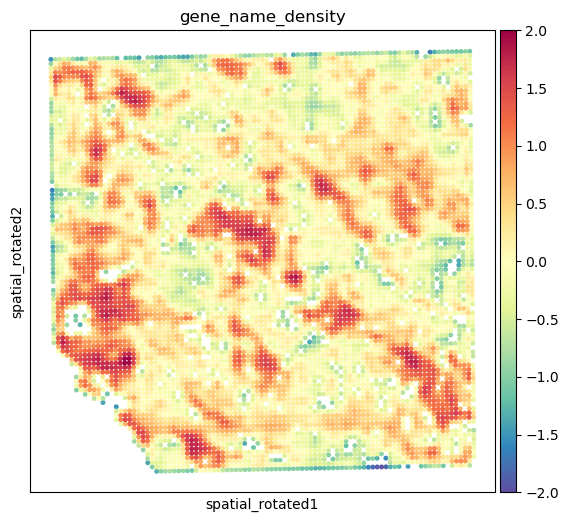

In [10]:
name = 'Diseased_57480'
    
slide = select_slide(adata, name, 'Sample')

with mpl.rc_context({'figure.figsize': [6.6,6],
                     'axes.facecolor': 'white'}):
    sc.pl.embedding(adata = slide, basis = 'spatial_rotated',
                    vmin = -2, vmax = 2,
                    color_map = 'Spectral_r', na_color = '#f0f4f9',
                    size = 50, color = ['gene_name_density'])

# Plot trajectory pseudotime

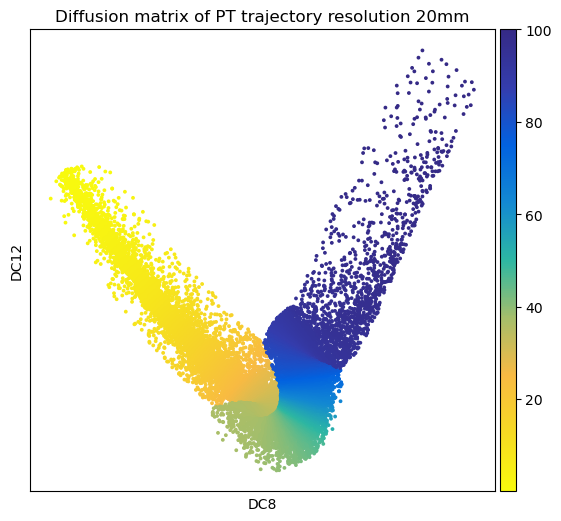

In [11]:
with mpl.rc_context({'figure.figsize': [6.6,6],
                     'axes.facecolor': 'white'}):
    sc.pl.diffmap(adata[~adata.obs["Trajectory"].isna()],
                  color = "Trajectory", dimensions = [(7,11)],
                  title = "Diffusion matrix of PT trajectory resolution 20mm", 
                  cmap = get_blueYellow_color(),
                  size = 30)

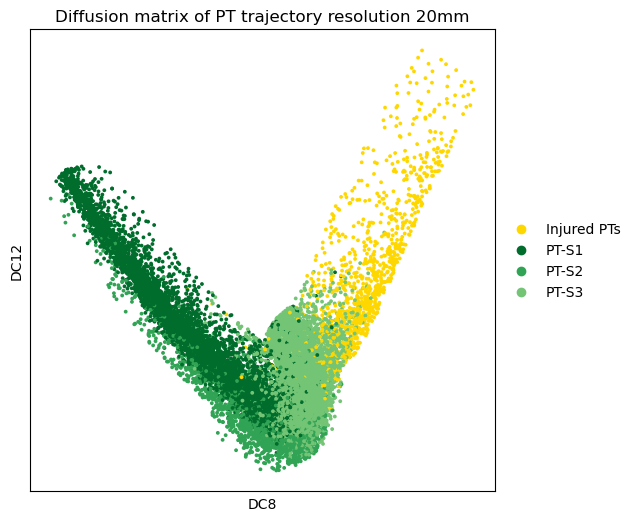

In [12]:
with mpl.rc_context({'figure.figsize': [6,6],
                     'axes.facecolor': 'white'}):
    sc.pl.diffmap(adata[~adata.obs["Trajectory"].isna()],
                  color = "Clusters2", dimensions = [(7,11)],
                  title = "Diffusion matrix of PT trajectory resolution 20mm", 
                  cmap = get_blueYellow_color(),
                  size = 30)

# Plot trajectory pseudotime in spatial image

In [13]:
adata = add_trajectory_density(adata)

Healthy_63079
Spatial coordinates shape: (8260, 2)
Expression matrix shape: (8260, 248455)
Spots in tissue: 8260


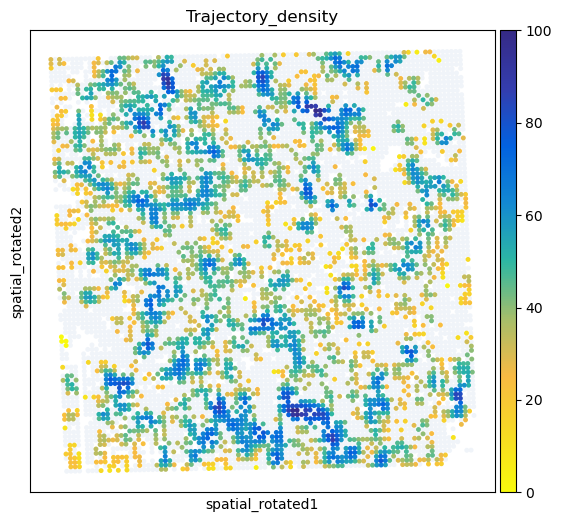

Diseased_57480
Spatial coordinates shape: (8398, 2)
Expression matrix shape: (8398, 248455)
Spots in tissue: 8398


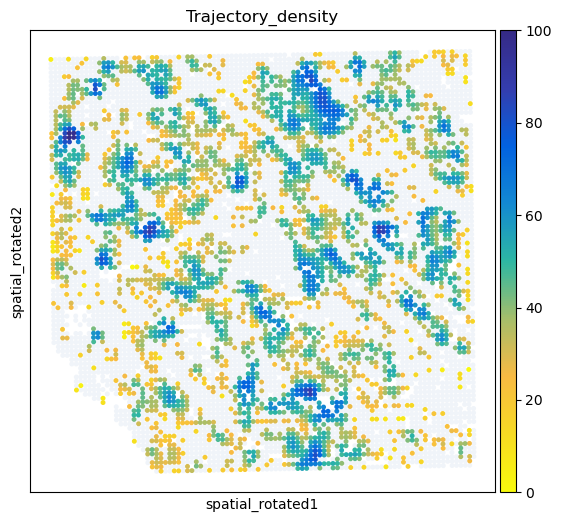

In [14]:
for name in ['Healthy_63079', 'Diseased_57480']:
    print(name)
    
    slide = select_slide(adata, name, 'Sample')
    # Check spatial data structure
    print("Spatial coordinates shape:", slide.obsm['spatial'].shape)
    print("Expression matrix shape:", slide.X.shape)
    print("Spots in tissue:", sum(slide.obs['in_tissue'] == 1))

    with mpl.rc_context({'figure.figsize': [6.6, 6],
                         'axes.facecolor': 'white'}):
        sc.pl.embedding(adata = slide, basis = 'spatial_rotated', vmin = 0, vmax = 100,
                        size = 50, color = ['Trajectory_density'], 
                        cmap = get_blueYellow_color(), na_color = '#f0f4f9')

# Plot each TF activity on spatial image

Healthy_63079


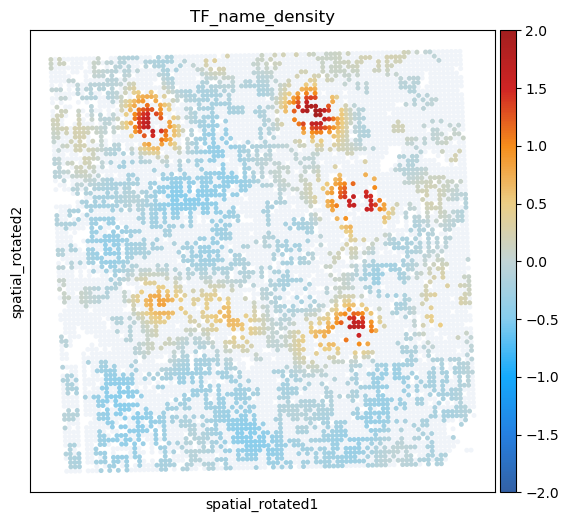

Diseased_57480


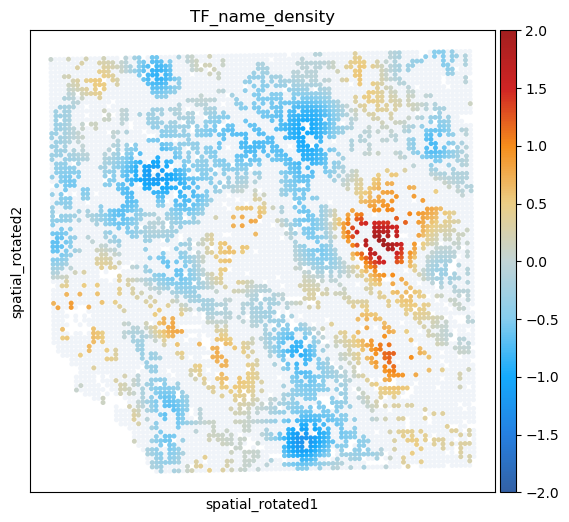

In [15]:
TF_name = 'BACH1'

adata = compute_TF_activity_kernel_density(adata, TF_name, trajectory_cells=True, adjust = 0.15)

for name in ['Healthy_63079', 'Diseased_57480']:
    print(name)
    
    slide = select_slide(adata, name, 'Sample')
    with mpl.rc_context({'figure.figsize': [6.6, 6],
                         'axes.facecolor': 'white'}):
        sc.pl.embedding(adata = slide, basis = 'spatial_rotated', vmin = -2, vmax = 2,
                       cmap = get_blueRed_color(), na_color = '#f0f4f9',
                       size = 50, color = ['TF_name_density'])

# Plot TF activity heatmap along PT trajectory

Creating Trajectory Group Matrix...
Smoothing...


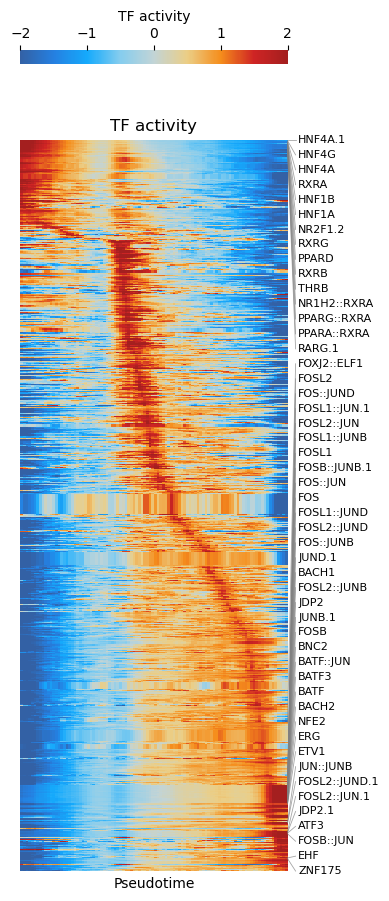

In [16]:
plot_trajectpry_activity_heatmap(adata, cmap = get_blueRed_color())

Creating Trajectory Group Matrix...
Smoothing...


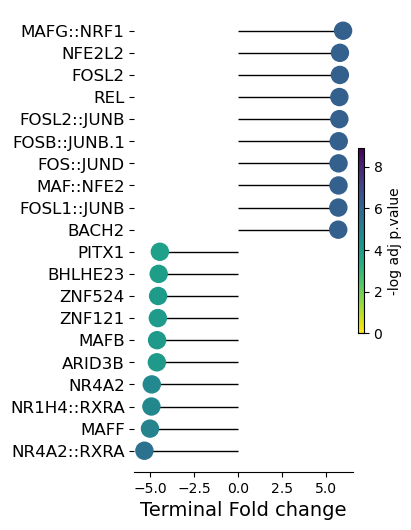

In [17]:
plot_top_trajectory_activity_terminal_fold_change(adata)

# Clone enrichment in cell type per sample

In [18]:
count_samples_clone(adata)

,Sample,Clusters2,clone,TSSEnrichment
0,Diseased_57480,CD,0,688
1,Diseased_57480,CD,1,5
2,Diseased_57480,PT-S1,0,1421
3,Diseased_57480,PT-S1,1,44
4,Diseased_57480,PT-S2,0,179
5,Diseased_57480,PT-S2,1,5
6,Diseased_78454,PT-S1,0,304
7,Diseased_78454,PT-S1,1,16
8,Healthy_63055,PT-S1,0,1262
9,Healthy_63055,PT-S1,1,15


# Differential TF activity clone vs non clone in specific cell type

clone
0    2224
1      11
Name: count, dtype: int64
['NKX6-3', 'ONECUT1', 'RARG.1', 'SIX3', 'MEIS1.1', 'HES5', 'HOXA5', 'DLX2', 'ZNF43', 'TCF7', 'TEAD1', 'SOX14', 'ZNF528', 'ZNF341', 'CTCF.1', 'SOX7', 'ATOH1', 'TBX6', 'PLAGL2', 'ZNF831']


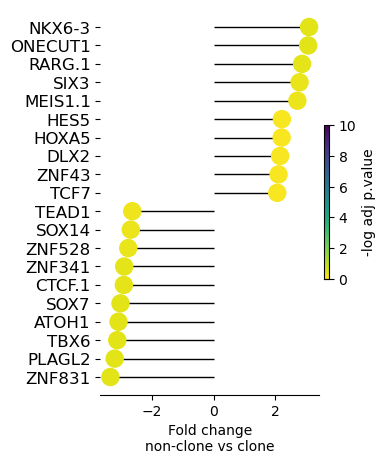

In [19]:
Differential_TF_activity_clone_vs_nonClone(adata, 'Healthy_63079', ['PT-S1'], 'clone')

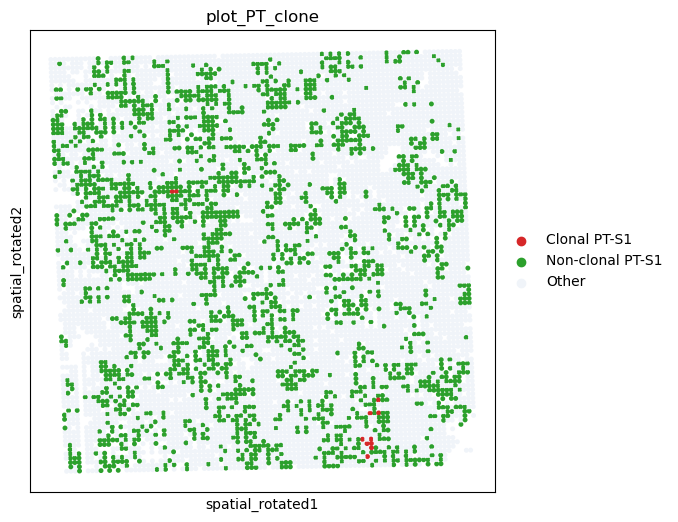

In [20]:
plot_clone_spatial_image(adata, 'Healthy_63079', ['PT-S1'], 'clone')

# Differential TF activity clone vs non clone in PTs population

PT_clone
0    3718
1      81
Name: count, dtype: int64
['RXRA', 'PPARD', 'RXRG', 'RXRB', 'HNF1A', 'HNF1B', 'DMRTC2', 'ZNF568', 'ZNF574', 'GSC::TBX21', 'KLF11', 'JUN::JUNB', 'JUND', 'KLF5', 'SP9', 'FOSB::JUNB.1', 'SOX6', 'SP2', 'FOSL1::JUND', 'SP4']


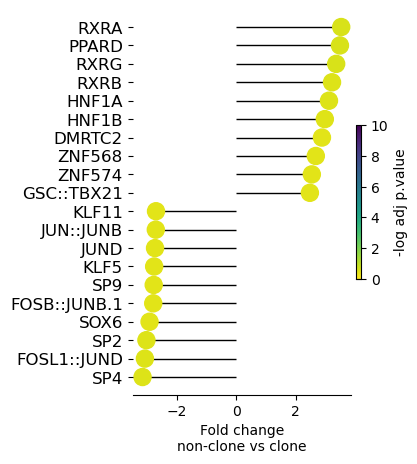

In [21]:
Differential_TF_activity_clone_vs_nonClone(adata, 'Diseased_57480', ['PT-S1', 'PT-S2', 'PT-S3', 'Injured PTs'], 'PT_clone')

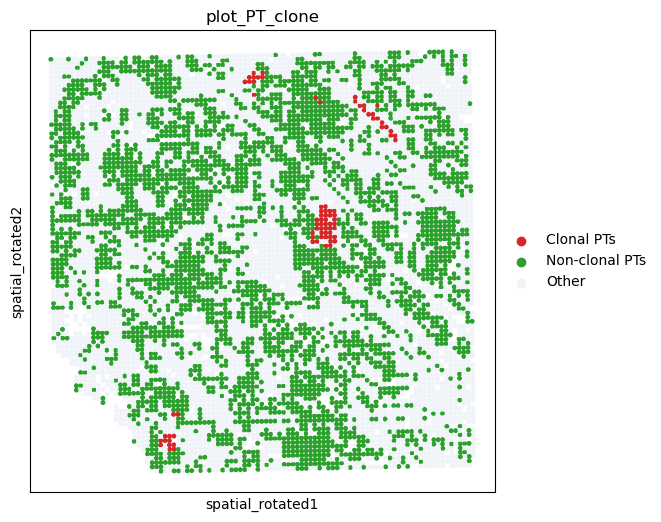

In [22]:
plot_clone_spatial_image(adata, 'Diseased_57480', ['PT-S1', 'PT-S2', 'PT-S3', 'Injured PTs'], 'PT_clone')

In [23]:
session_info.show(excludes=['backports'])